In [2]:
# 1. IMPORT LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)

sns.set_theme(style='whitegrid', palette='Set2')
RANDOM_STATE = 42

In [3]:
# 2. LOAD THE DATASET
df = pd.read_csv('adult.csv')

print('Dataset shape:', df.shape)
display(df.head())

Dataset shape: (32561, 15)


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [4]:
# 3. INSPECT DATA QUALITY
print('Column data types:\n', df.dtypes.value_counts())
# The adult dataset uses '?' to denote missing data
print('\nMissing values (denoted as "?"):', (df == '?').sum().sum())
print('Duplicate rows:', int(df.duplicated().sum()))
print('\nOriginal class counts:\n', df['income'].value_counts())
display(df.describe().T.head(10))

Column data types:
 str      9
int64    6
Name: count, dtype: int64

Missing values (denoted as "?"): 4262
Duplicate rows: 24

Original class counts:
 income
<=50K    24720
>50K      7841
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education.num,32561.0,10.080679,2.572720,1.0,9.0,10.0,12.0,16.0
capital.gain,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,99999.0
capital.loss,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,4356.0
hours.per.week,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0


In [5]:
# 4. PREPROCESS THE DATA
# Remove duplicate observations
df = df.drop_duplicates().copy()

# Replace '?' with NaN and drop rows with missing values
df.replace('?', np.nan, inplace=True)
df.dropna(inplace=True)

# Encode the target: '>50K' = 1 and '<=50K' = 0
df['income'] = df['income'].map({'<=50K': 0, '>50K': 1})

# Separate features and target
X = df.drop(columns=['income'])
y = df['income'].astype(int)

# One-Hot Encode categorical variables for the machine learning model
X = pd.get_dummies(X, drop_first=True)

print('Feature matrix:', X.shape)
print('Target vector:', y.shape)
print('Remaining missing values:', int(X.isna().sum().sum()))

Feature matrix: (30139, 96)
Target vector: (30139,)
Remaining missing values: 0


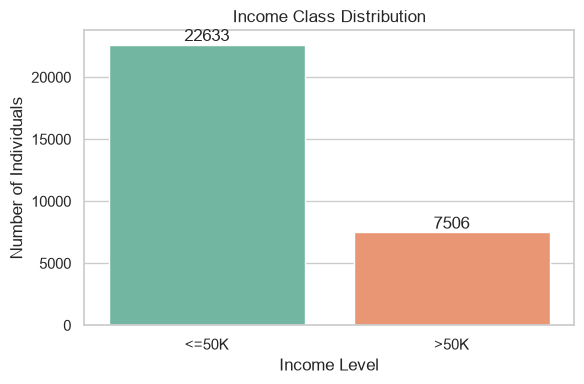

In [6]:
# 5. VISUALIZE CLASS DISTRIBUTION
class_counts = y.map({0: '<=50K', 1: '>50K'}).value_counts()

plt.figure(figsize=(6, 4))
ax = sns.barplot(x=class_counts.index, y=class_counts.values, hue=class_counts.index, legend=False)
for container in ax.containers:
    ax.bar_label(container)
plt.title('Income Class Distribution')
plt.xlabel('Income Level')
plt.ylabel('Number of Individuals')
plt.tight_layout()
plt.show()

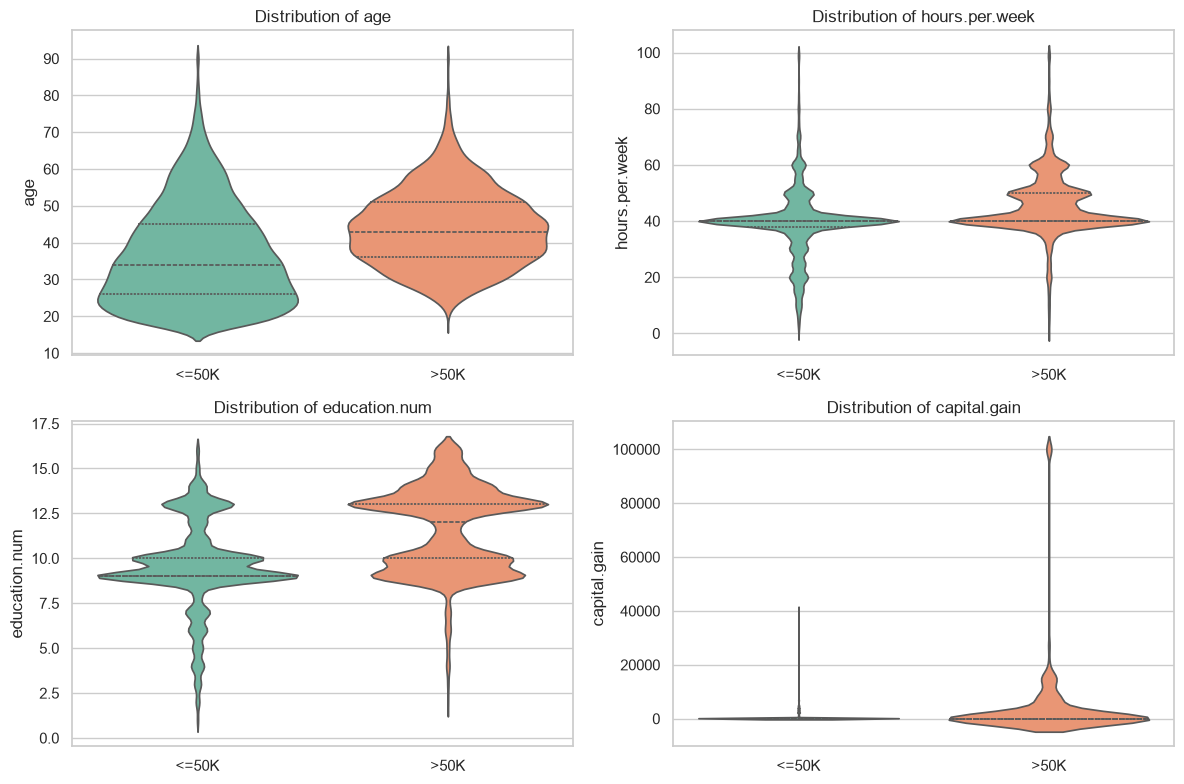

In [14]:
# 6. VISUALIZE REPRESENTATIVE FEATURE DISTRIBUTIONS (Violin Plot Alternative)
plot_df = df.assign(Income_Level=y.map({0: '<=50K', 1: '>50K'}))
selected_features = ['age', 'hours.per.week', 'education.num', 'capital.gain']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feature, ax in zip(selected_features, axes.ravel()):
    sns.violinplot(
        data=plot_df, 
        x='Income_Level', 
        y=feature, 
        hue='Income_Level',
        palette='Set2', 
        inner='quartile', # Shows the median and quartiles inside the violin
        ax=ax
    )
    ax.set_title(f'Distribution of {feature}')
    ax.set_xlabel('') # Removes redundant x-axis labels

plt.tight_layout()
plt.show()

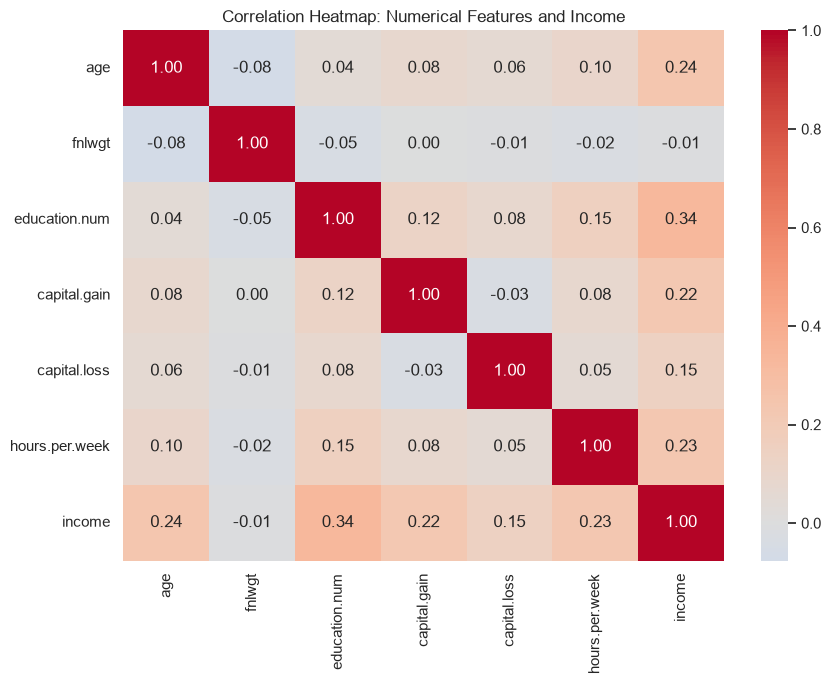

In [8]:
# 7. VISUALIZE CORRELATIONS AMONG NUMERICAL FEATURES
# Filtering out the heavily expanded dummy columns to just view continuous relationships
correlation_features = ['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week', 'income']

plt.figure(figsize=(9, 7))
sns.heatmap(df[correlation_features].corr(), cmap='coolwarm', center=0, annot=True, fmt=".2f")
plt.title('Correlation Heatmap: Numerical Features and Income')
plt.tight_layout()
plt.show()

In [9]:
# 8. TRAIN-TEST SPLIT AND FEATURE SCALING
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# Fit the scaler only on training data to prevent data leakage
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns, index=X_test.index
)

print('Training set:', X_train_scaled.shape)
print('Testing set:', X_test_scaled.shape)
print('Training class proportions:\n', y_train.value_counts(normalize=True).sort_index())

Training set: (24111, 96)
Testing set: (6028, 96)
Training class proportions:
 income
0    0.750944
1    0.249056
Name: proportion, dtype: float64


In [10]:
# 9. IMPLEMENT RANDOM FOREST CLASSIFIER
# Random Forest is highly effective for datasets like adult.csv with complex categorical interactions
model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
model.fit(X_train_scaled, y_train)

# Predict classes and probabilities for the unseen test set
y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:, 1]

comparison = pd.DataFrame({
    'Actual': y_test.map({0: '<=50K', 1: '>50K'}),
    'Predicted': pd.Series(y_pred, index=y_test.index).map({0: '<=50K', 1: '>50K'}),
    'P(>50K)': y_proba
})
display(comparison.head(10))

,Actual,Predicted,P(>50K)
19124,<=50K,<=50K,0.00
28580,<=50K,<=50K,0.00
13341,>50K,<=50K,0.18
26889,<=50K,<=50K,0.00
16846,<=50K,<=50K,0.00
26784,<=50K,<=50K,0.09
19746,<=50K,>50K,0.53
755,>50K,>50K,0.98
3013,>50K,>50K,0.72
23409,<=50K,<=50K,0.00


In [11]:
# 10. EVALUATE THE MODEL
metrics = pd.Series({
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall (Sensitivity)': recall_score(y_test, y_pred),
    'F1-score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_proba)
}).round(4)

print('Evaluation Metrics:\n', metrics)
print('\nConfusion Matrix:\n', confusion_matrix(y_test, y_pred))
print('\nClassification Report:\n')
print(classification_report(
    y_test, y_pred, target_names=['<=50K', '>50K'], digits=4
))

Evaluation Metrics:
 Accuracy                0.8535
Precision               0.7330
Recall (Sensitivity)    0.6476
F1-score                0.6877
ROC-AUC                 0.9067
dtype: float64

Confusion Matrix:
 [[4173  354]
 [ 529  972]]

Classification Report:

              precision    recall  f1-score   support

       <=50K     0.8875    0.9218    0.9043      4527
        >50K     0.7330    0.6476    0.6877      1501

    accuracy                         0.8535      6028
   macro avg     0.8103    0.7847    0.7960      6028
weighted avg     0.8490    0.8535    0.8504      6028



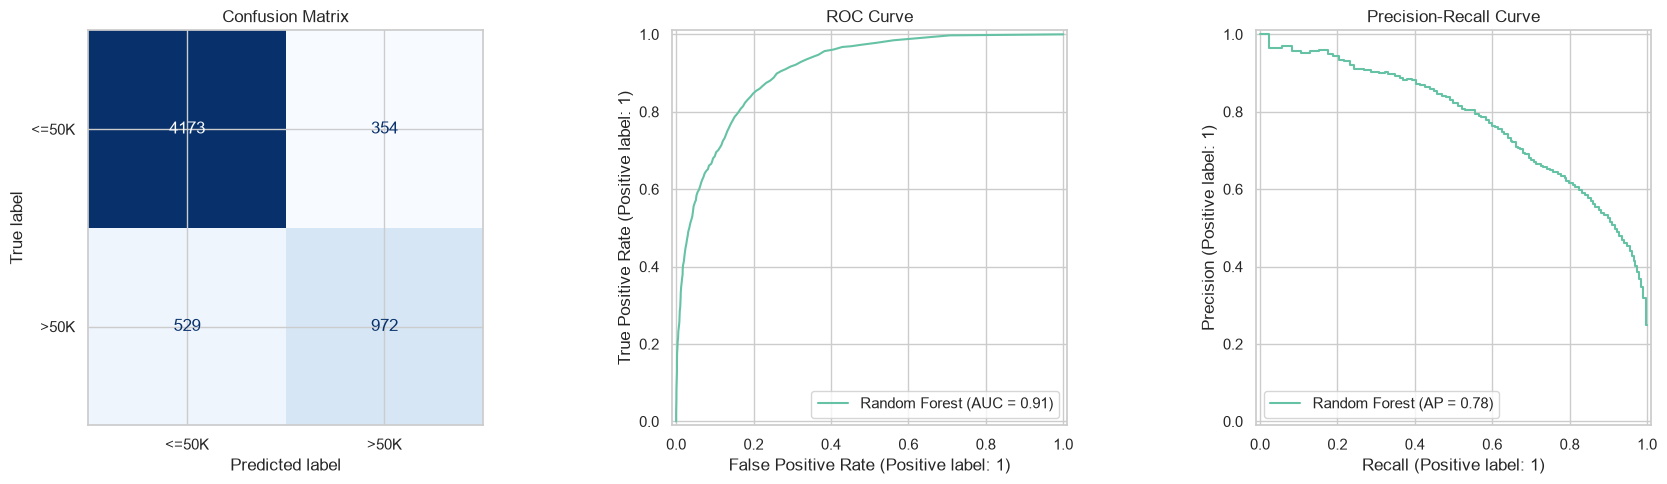

In [12]:
# 11. VISUALIZE MODEL PERFORMANCE
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['<=50K', '>50K'],
    cmap='Blues', colorbar=False, ax=axes[0]
)
axes[0].set_title('Confusion Matrix')

RocCurveDisplay.from_predictions(
    y_test, y_proba, name='Random Forest', ax=axes[1]
)
axes[1].set_title('ROC Curve')

PrecisionRecallDisplay.from_predictions(
    y_test, y_proba, name='Random Forest', ax=axes[2]
)
axes[2].set_title('Precision-Recall Curve')

plt.tight_layout()
plt.show()